# **Logistic Regression & classification model evaluation**

In this notebook we will look at **Logistic Regression** and **evaluation of classification models**.

Do some imports.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

For this notebook we will use the **Iris dataset**.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()  # loading the dataset
list(iris)  # what the prepared data contains

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

Let's look at the features and their values:

In [3]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [4]:
iris.data

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [5]:
iris.data.shape

(150, 4)

Let's look at the output variable (the target) values and what do they mean:

In [6]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [7]:
iris.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

For demonstration purposes, we will work only with the third column (Petal length) and will make it into a binary classification task: Virginica vs. Others.

In [8]:
X = iris.data[:, 3].reshape(-1, 1)  # take third column and reshape to get a column vector
y = iris.target_names[iris.target] == 'virginica'  # make it into binary classification with Virginica vs. Others

Visualize the data.

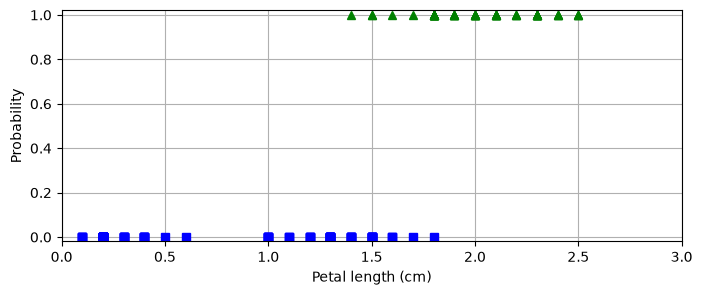

In [9]:
plt.figure(figsize=(8, 3))
plt.plot(X[y == 0], y[y == 0], "bs")
plt.plot(X[y == 1], y[y == 1], "g^")
plt.xlabel("Petal length (cm)")
plt.ylabel("Probability")
plt.axis([0, 3, -0.02, 1.02])
plt.grid()
plt.show()

Train Logistic Regression model without regularization (C = 1E6).

In [10]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(C=1e6, random_state=42)
log_reg.fit(X, y)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1000000.0
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the follo

Let's plot it.

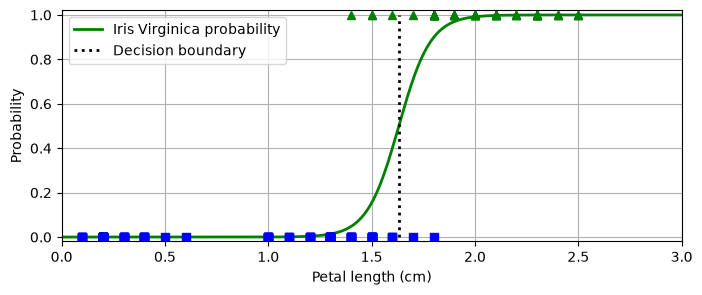

In [11]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)  # reshape to get a column vector
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

plt.figure(figsize=(8, 3))
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris Virginica probability")
plt.plot([decision_boundary, decision_boundary], [0, 1], "k:", linewidth=2, label="Decision boundary")

plt.plot(X[y == 0], y[y == 0], "bs")
plt.plot(X[y == 1], y[y == 1], "g^")
plt.xlabel("Petal length (cm)")
plt.ylabel("Probability")
plt.legend(loc="upper left")
plt.axis([0, 3, -0.02, 1.02])
plt.grid()
plt.show()

Let's try the same with the default regularization (C = 1).

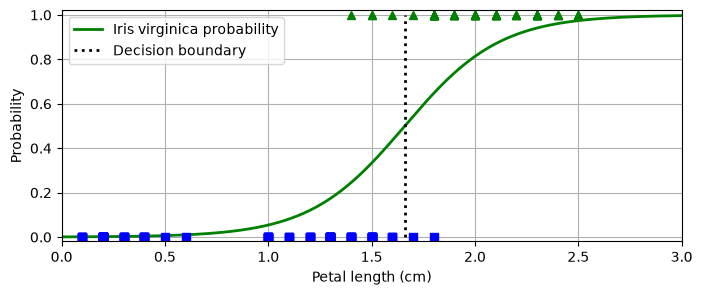

In [12]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X, y)

X_new = np.linspace(0, 3, 1000).reshape(-1, 1)  # reshape to get a column vector
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

plt.figure(figsize=(8, 3))
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris virginica probability")
plt.plot([decision_boundary, decision_boundary], [0, 1], "k:", linewidth=2, label="Decision boundary")

plt.plot(X[y == 0], y[y == 0], "bs")
plt.plot(X[y == 1], y[y == 1], "g^")
plt.xlabel("Petal length (cm)")
plt.ylabel("Probability")
plt.legend(loc="upper left")
plt.axis([0, 3, -0.02, 1.02])
plt.grid()
plt.show()

Where is the decision bounrary?

In [13]:
decision_boundary

np.float64(1.6606606606606606)

In [14]:
log_reg.predict_proba([[1.5], [1.7]])

array([[0.66699864, 0.33300136],
       [0.45713982, 0.54286018]])

In [15]:
log_reg.predict([[1.5], [1.7]])

array([False,  True])

## **Let's evaluate the model**

We will be using the **Stratified Cross-Validation**. And then compute Accuracy, Precision, Recall, and F1.

We could use one of these:
* `cross_val_score()` - gives one score.
* `cross_validate()` - gives multiple scores.
* `cross_val_predict()` - this will give different results if Cross-Validation subsets are not the same size accross all folds. Be careful.

In [16]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score

skfcv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
yHat = cross_val_predict(log_reg, X, y, cv=skfcv)
print('Accuracy:', accuracy_score(y, yHat))

Accuracy: 0.96


## Confusion Matrix

In [17]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y, yHat)

array([[98,  2],
       [ 4, 46]])

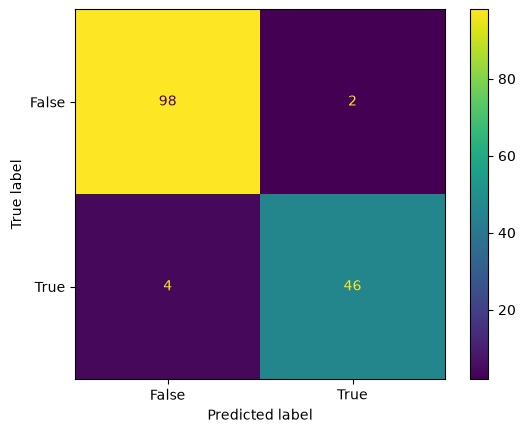

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y, yHat)

## Classification Report

In [19]:
from sklearn.metrics import classification_report

print(classification_report(y, yHat, target_names=['Not Virginica', 'Virginica'], zero_division=0, digits=4))

               precision    recall  f1-score   support

Not Virginica     0.9608    0.9800    0.9703       100
    Virginica     0.9583    0.9200    0.9388        50

     accuracy                         0.9600       150
    macro avg     0.9596    0.9500    0.9545       150
 weighted avg     0.9600    0.9600    0.9598       150



## **Precision/Recall Trade-off**

You can define any threshold. There is no law to always use 0.5.

In [20]:
log_reg.predict([[1.5], [1.7]])

array([False,  True])

In [21]:
log_reg.predict_proba([[1.5], [1.7]])

array([[0.66699864, 0.33300136],
       [0.45713982, 0.54286018]])

In [22]:
log_reg.predict_proba([[1.5], [1.7]])[:, 1]

array([0.33300136, 0.54286018])

In [23]:
threshold = 0.7
log_reg.predict_proba([[1.5], [1.7]])[:, 1] >= threshold

array([False, False])

To plot Precision and Recall, we will be using `cross_val_predict` with the `predict_proba` function to compute probability of Class 1 for each data point.

In [24]:
y_prob = cross_val_predict(log_reg, X, y, cv=skfcv, method="predict_proba")[:, 1]
y_prob

array([0.00235636, 0.00258275, 0.00220966, 0.00207489, 0.00207489,
       0.00495378, 0.00370562, 0.00235636, 0.00218771, 0.00158804,
       0.00218771, 0.00215238, 0.00145265, 0.00141781, 0.00184737,
       0.00551669, 0.00510567, 0.00335985, 0.0033172 , 0.00326628,
       0.00258275, 0.00536309, 0.00245038, 0.0072651 , 0.00243066,
       0.00218771, 0.00478799, 0.00184737, 0.00240629, 0.00220966,
       0.00218771, 0.00478799, 0.00156079, 0.00245038, 0.00184737,
       0.00240629, 0.00243066, 0.0016116 , 0.00215238, 0.00218771,
       0.00315279, 0.00326628, 0.00240629, 0.01001595, 0.00560027,
       0.0033172 , 0.00235636, 0.00245038, 0.00243066, 0.00218771,
       0.26295674, 0.35115562, 0.33258132, 0.17669637, 0.35115562,
       0.18386114, 0.45077103, 0.06162492, 0.17669637, 0.25055837,
       0.06446715, 0.3161365 , 0.06446715, 0.241915  , 0.19085668,
       0.25425491, 0.32678869, 0.06162492, 0.3397772 , 0.07797258,
       0.64808707, 0.17340676, 0.3488461 , 0.12119776, 0.16508

Now we can use those probabilities to get Precisions and Recalls for all possible thresholds.

In [25]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y, y_prob)

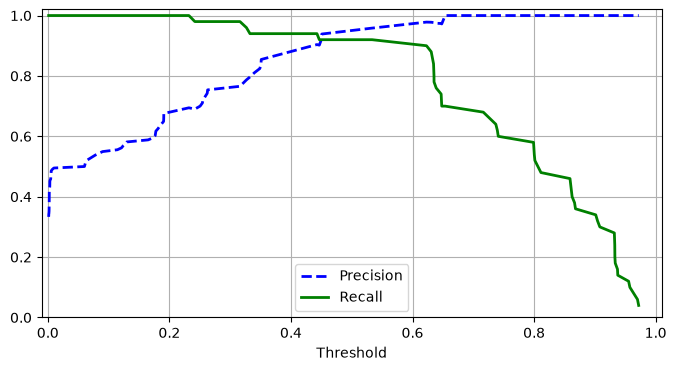

In [26]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.grid()
plt.xlabel("Threshold")
plt.legend(loc="lower center")
plt.axis([-0.01, 1.01, 0, 1.02])
plt.show()

Now let's plot the Precision-Recall curve.

It is desired that a model should have both high Precision and high Recall. However, most of the time it involves a trade-off between the two. Usually, people would be very happy to see such curve as we got. It shows high Precision and high Recall everywhere.

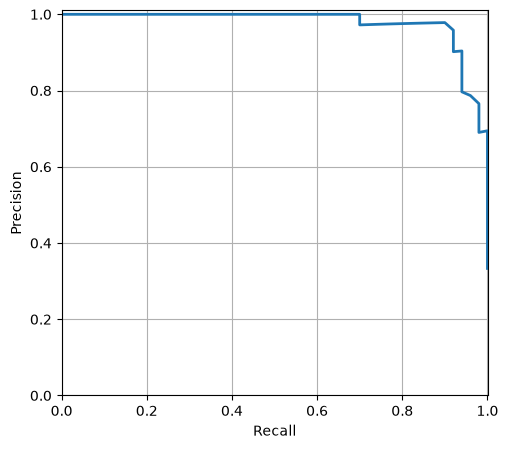

In [27]:
plt.figure(figsize=(5.5, 5))
plt.plot(recalls, precisions, linewidth=2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1.001, 0, 1.01])
plt.grid()
plt.show()

# **Logistic Regression with two features**

For this demonstration, we will take features 2 and 3.

In [28]:
X = iris.data[:, (2, 3)]
y = iris.target_names[iris.target] == 'versicolor'

And we will standardize the data.

In [29]:
# https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Plot the data.

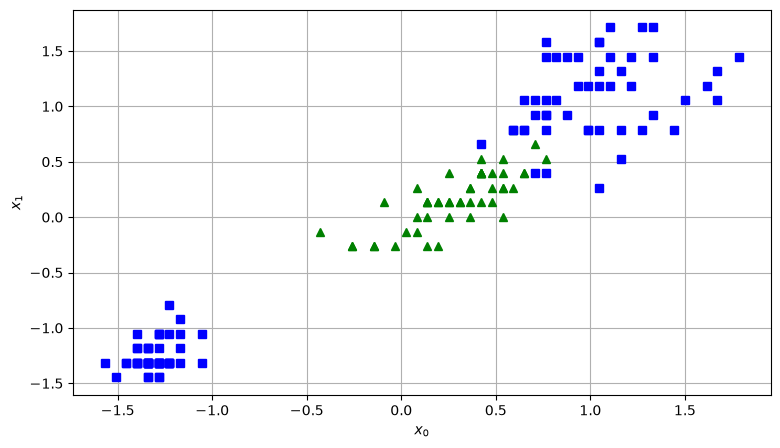

In [30]:
plt.figure(figsize=(9, 5))
plt.plot(X[y == 1, 0], X[y == 1, 1], "g^", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Others")
plt.xlabel("$x_0$")
plt.ylabel("$x_1$")
plt.grid()
plt.show()

Create a model.

In [31]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X, y)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

Plot the data together with the decision boundaries of the model.

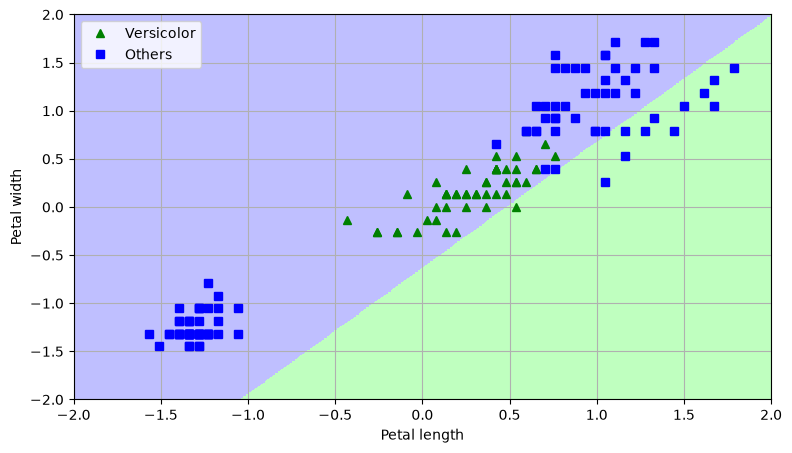

In [32]:
from matplotlib.colors import ListedColormap

# to plot the decision boundaries, we have to create a grid of x0,x1 values
x0, x1 = np.meshgrid(np.linspace(-2, 2, 500).reshape(-1, 1), np.linspace(-2, 2, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

# predict y for each x0,x1 and reshape back to grid
zz = log_reg.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(9, 5))
plt.plot(X[y == 1, 0], X[y == 1, 1], "g^", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Others")

custom_cmap = ListedColormap(["#bfbfff", "#bfffbf"])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.grid()
plt.show()

Now we evaluate the model using 10-fold Cross-Validation and all the measures that we have introduced.

In [33]:
yHat = cross_val_predict(log_reg, X, y, cv=skfcv)

In [34]:
confusion_matrix(y, yHat)

array([[89, 11],
       [49,  1]])

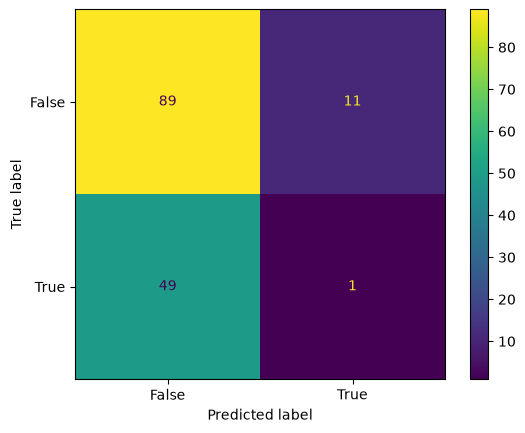

In [35]:
ConfusionMatrixDisplay.from_predictions(y, yHat)

In [36]:
print(classification_report(y, yHat, target_names=['Not Versicolor', 'Versicolor'], zero_division=0, digits=4))

                precision    recall  f1-score   support

Not Versicolor     0.6449    0.8900    0.7479       100
    Versicolor     0.0833    0.0200    0.0323        50

      accuracy                         0.6000       150
     macro avg     0.3641    0.4550    0.3901       150
  weighted avg     0.4577    0.6000    0.5094       150



## **Let's try second degree polynomial**

First, create 2nd degree polynomial feature.

In [37]:
from sklearn.preprocessing import PolynomialFeatures

In [38]:
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(X)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_poly, y)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

Note that we need the feature transform for the plot as well.

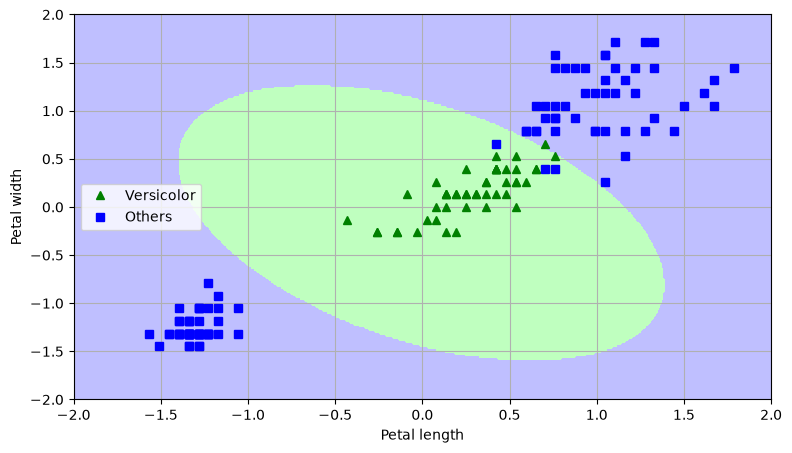

In [39]:
x0, x1 = np.meshgrid(np.linspace(-2, 2, 500).reshape(-1, 1), np.linspace(-2, 2, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

X_new = poly_features.fit_transform(X_new)  # ADDITIONAL CODE WHEN WE HAVE HIGHER DEGREE LOGISTIC REGRESSION

zz = log_reg.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(9, 5))
plt.plot(X[y == 1, 0], X[y == 1, 1], "g^", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Others")

custom_cmap = ListedColormap(["#bfbfff", "#bfffbf"])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="center left")
plt.grid()
plt.show()

Evaluate the model.

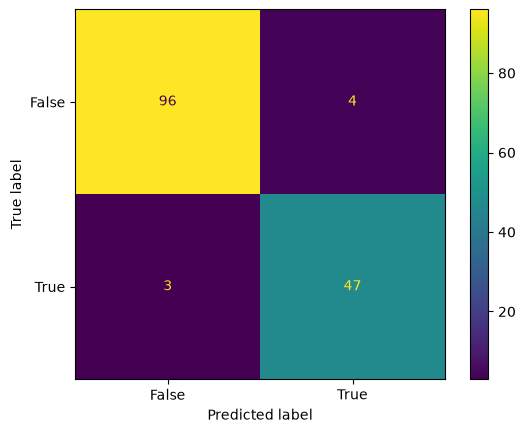

In [40]:
yHat = cross_val_predict(log_reg, X_poly, y, cv=skfcv)
ConfusionMatrixDisplay.from_predictions(y, yHat)

In [41]:
print(classification_report(y, yHat, target_names=['Not Versicolor', 'Versicolor'], zero_division=0, digits=4))

                precision    recall  f1-score   support

Not Versicolor     0.9697    0.9600    0.9648       100
    Versicolor     0.9216    0.9400    0.9307        50

      accuracy                         0.9533       150
     macro avg     0.9456    0.9500    0.9478       150
  weighted avg     0.9537    0.9533    0.9534       150



# **All three classes**

Now let's try the same processing with all three classes that the dataset offers.

In [42]:
X = iris.data[:, (2, 3)]
y = iris.target

scaler = StandardScaler().fit(X)
X = scaler.transform(X)

In [43]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X, y)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

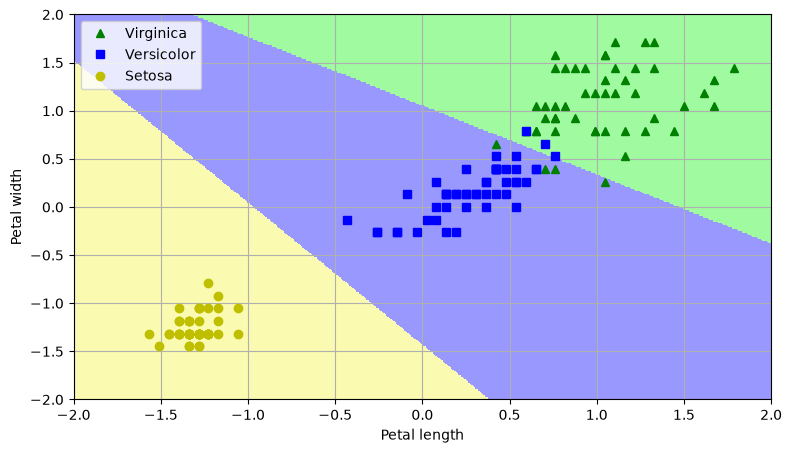

In [44]:
x0, x1 = np.meshgrid(np.linspace(-2, 2, 500).reshape(-1, 1), np.linspace(-2, 2, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

zz =  log_reg.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(9, 5))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Setosa")

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.grid()
plt.show()

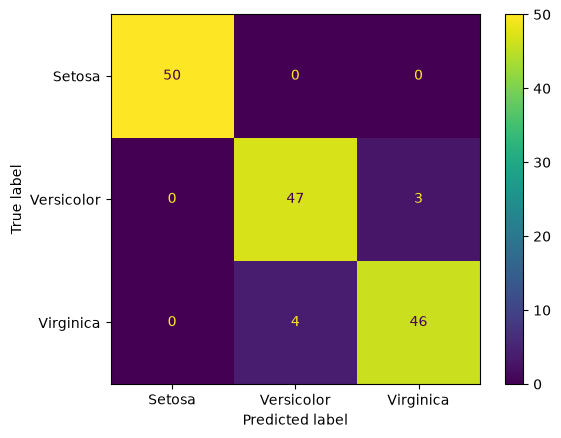

In [45]:
yHat = cross_val_predict(log_reg, X, y, cv=skfcv)
ConfusionMatrixDisplay.from_predictions(y, yHat, display_labels=['Setosa', 'Versicolor', 'Virginica'])

In [46]:
print(classification_report(y, yHat, target_names=['Setosa', 'Versicolor', 'Virginica'], zero_division=0, digits=4))

              precision    recall  f1-score   support

      Setosa     1.0000    1.0000    1.0000        50
  Versicolor     0.9216    0.9400    0.9307        50
   Virginica     0.9388    0.9200    0.9293        50

    accuracy                         0.9533       150
   macro avg     0.9534    0.9533    0.9533       150
weighted avg     0.9534    0.9533    0.9533       150



You can also try 2nd degree. Run this code and go back to the plotting cell to see the result and evaluations. Note that you will have to uncomment the one commented-out line in the plotting code.

In [47]:
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(X)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_poly, y)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

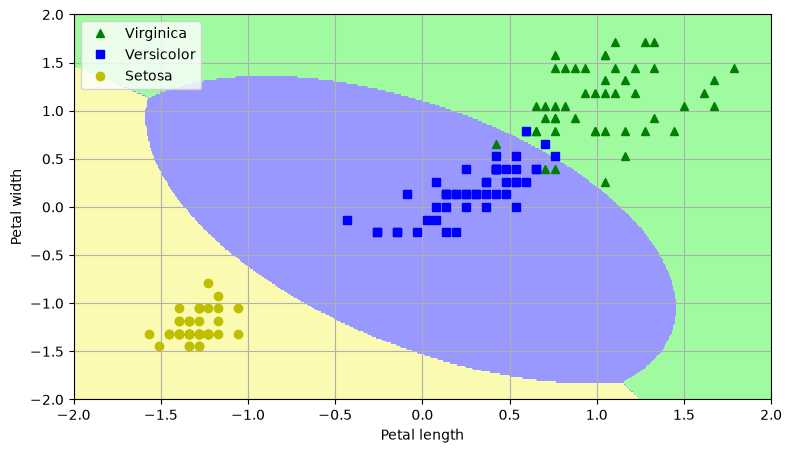

In [48]:
x0, x1 = np.meshgrid(np.linspace(-2, 2, 500).reshape(-1, 1), np.linspace(-2, 2, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

X_new = poly_features.fit_transform(X_new)  # ADDITIONAL CODE WHEN WE HAVE HIGHER DEGREE LOGISTIC REGRESSION

zz =  log_reg.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(9, 5))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Setosa")

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.grid()
plt.show()

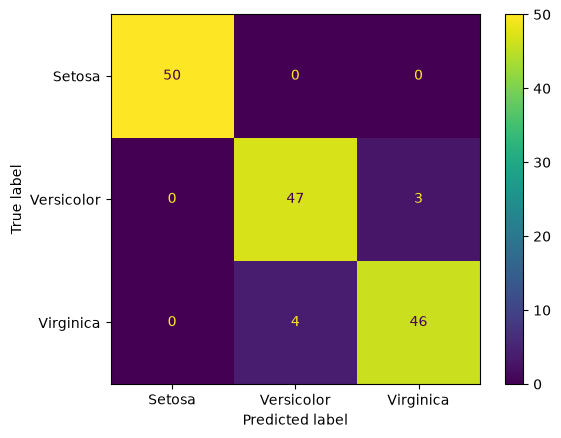

In [49]:
yHat = cross_val_predict(log_reg, X_poly, y, cv=skfcv)
ConfusionMatrixDisplay.from_predictions(y, yHat, display_labels=['Setosa', 'Versicolor', 'Virginica'])

In [50]:
print(classification_report(y, yHat, target_names=['Setosa', 'Versicolor', 'Virginica'], zero_division=0, digits=4))

              precision    recall  f1-score   support

      Setosa     1.0000    1.0000    1.0000        50
  Versicolor     0.9216    0.9400    0.9307        50
   Virginica     0.9388    0.9200    0.9293        50

    accuracy                         0.9533       150
   macro avg     0.9534    0.9533    0.9533       150
weighted avg     0.9534    0.9533    0.9533       150



## Let's try different C values for regularization

In [51]:
from sklearn.metrics import f1_score

Cs = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
scores = np.empty(len(Cs))

for i, C in enumerate(Cs):
  log_reg = LogisticRegression(C=C, random_state=42)
  yHat = cross_val_predict(log_reg, X, y, cv=skfcv)
  scores[i] = f1_score(y, yHat, average='macro')
  print(f'F1 score for C={C}:\t{scores[i]}')

F1 score for C=0.0001:	0.5411255411255411
F1 score for C=0.001:	0.5995705850778315
F1 score for C=0.01:	0.827176864571764
F1 score for C=0.1:	0.9533286661999533
F1 score for C=1:	0.9533286661999533
F1 score for C=10:	0.9533286661999533
F1 score for C=100:	0.9533286661999533
F1 score for C=1000:	0.9533286661999533


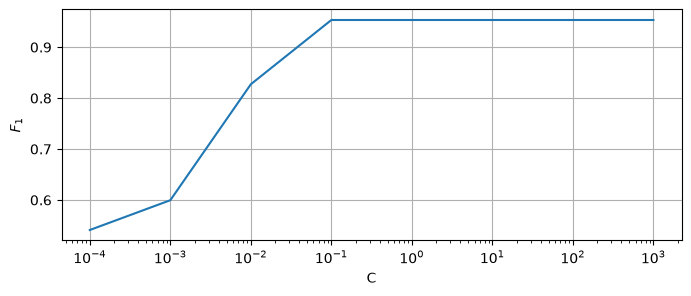

In [52]:
plt.figure(figsize=(8, 3))
plt.plot(Cs, scores, "-")
plt.xscale('log')
plt.xlabel("C")
plt.ylabel("$F_1$")
plt.grid()
plt.show()

<br>
<br>
<br>
<br>
<br>
<br>

---
<small>*Notebook by Gints Jēkabsons. Some parts of the code are based on the book <a href="https://www.oreilly.com/library/view/hands-on-machine-learning/9781098125967/" target="_blank">“Hands-On Machine Learning”</a> and it's <a href="https://github.com/ageron/handson-ml3" target="_blank">GitHub repo.</a>*</small>